In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

# Scoring Documents and the Importance of a Direction

## The example

Four documents and three words, as in the SVD notebook. The matrix $X$ has documents in the rows and words in the columns, so $X \in \mathbb{R}^{4 \times 3}$.

In [2]:
words = ["data", "model", "rare"]
documents = ["doc1", "doc2", "doc3", "doc4"]

counts = np.array([
    [2, 1, 0],
    [1, 2, 0],
    [1, 0, 0],
    [1, 0, 3],
])

X = pd.DataFrame(counts, index=documents, columns=words)
X

,data,model,rare
doc1,2,1,0
doc2,1,2,0
doc3,1,0,0
doc4,1,0,3


## What is a score?

A **direction** in word space is a vector $w \in \mathbb{R}^3$ with one weight per word. We use unit vectors, $\lVert w \rVert = 1$, so that directions can be compared fairly.

The **score** of a document $d$ in direction $w$ is the dot product of its row $x_d$ with $w$:

$$
s_d = x_d \cdot w = \sum_{j} X_{dj} \, w_j
$$

For all documents at once, the score vector is the matrix-vector product

$$
s = X w, \qquad (4 \times 3)(3 \times 1) = 4 \times 1 .
$$

A score says how strongly a document points in the direction $w$: a document that uses the words with large weights gets a large score.

### Scoring with the direction "only `data`"

With $w = (1, 0, 0)$ the score is just the count of the word `data`.

In [3]:
w_data = np.array([1.0, 0.0, 0.0])

scores_data = X.to_numpy() @ w_data
pd.DataFrame({"score": scores_data}, index=documents)

,score
doc1,2.0
doc2,1.0
doc3,1.0
doc4,1.0


### Scoring with a mixture of words

With $w = (1, 1, 0) / \sqrt{2}$ a document gets credit for both `data` and `model`. We divide by $\sqrt{2}$ so that $\lVert w \rVert = 1$.

In [4]:
w_mix = np.array([1.0, 1.0, 0.0]) / np.sqrt(2)

print("Length of w_mix:", np.linalg.norm(w_mix))

scores_mix = X.to_numpy() @ w_mix
pd.DataFrame({"score": scores_mix}, index=documents)

Length of w_mix: 0.9999999999999999


,score
doc1,2.121320
doc2,2.121320
doc3,0.707107
doc4,0.707107


## The importance of a direction

Different directions give different scores. We summarize how much a direction "sees" in the data by the total squared score:

$$
\text{importance}(w) = \sum_{d} s_d^2 = \lVert X w \rVert^2 = w^\top X^\top X \, w
$$

The last form is the key identity: $(Xw)^\top (Xw) = w^\top X^\top X w$. The importance of a direction depends on the data only through the word similarity matrix $X^\top X$.

In [5]:
XtX = X.to_numpy().T @ X.to_numpy()
pd.DataFrame(XtX, index=words, columns=words)

,data,model,rare
data,7,4,3
model,4,5,0
rare,3,0,9


In [6]:
def importance(direction):
    """Total squared score of all documents in the given direction"""
    scores = X.to_numpy() @ direction
    return np.sum(scores ** 2)

# Two ways to compute the same number
for name, direction in [("only data", w_data), ("data + model", w_mix)]:
    print(f"{name:13s}  sum of squared scores = {importance(direction):.3f}   w' X'X w = {direction @ XtX @ direction:.3f}")

only data      sum of squared scores = 7.000   w' X'X w = 7.000
data + model   sum of squared scores = 10.000   w' X'X w = 10.000


## Which direction is the most important?

We try many unit vectors and compute the importance of each. Directions are drawn at random (with a fixed seed) and normalized to length 1.

In [7]:
rng = np.random.default_rng(42)

random_directions = rng.normal(size=(20000, 3))
random_directions = random_directions / np.linalg.norm(random_directions, axis=1, keepdims=True)

random_importance = np.einsum("ij,jk,ik->i", random_directions, XtX, random_directions)

print("Smallest importance among 20000 random directions:", random_importance.min().round(3))
print("Largest importance among 20000 random directions: ", random_importance.max().round(3))

Smallest importance among 20000 random directions: 1.388
Largest importance among 20000 random directions:  12.125


Now the eigendecomposition of $X^\top X$ (the eigenvalues $\lambda_j$ and the eigenvectors $v_j$):

In [8]:
eigenvalues, V = np.linalg.eigh(XtX)

order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
V = V[:, order]

pd.DataFrame(V, index=words, columns=["v1", "v2", "v3"])

,v1,v2,v3
data,0.668663,-0.364722,-0.647973
model,0.375375,-0.586667,0.717576
rare,0.641860,0.723049,0.255375


In [9]:
print("Eigenvalues:", eigenvalues)
print("Importance of v1, v2, v3:", [round(float(importance(V[:, j])), 3) for j in range(3)])

Eigenvalues: [12.125  7.487  1.388]
Importance of v1, v2, v3: [12.125, 7.487, 1.388]


The importance of an eigenvector $v_j$ equals its eigenvalue $\lambda_j$:

$$
\lVert X v_j \rVert^2 = v_j^\top X^\top X v_j = v_j^\top (\lambda_j v_j) = \lambda_j \, v_j^\top v_j = \lambda_j .
$$

The largest and smallest random importance values are close to $\lambda_1$ and $\lambda_3$ but never beyond them. The plot shows the importance of all random directions with the eigenvalues marked.

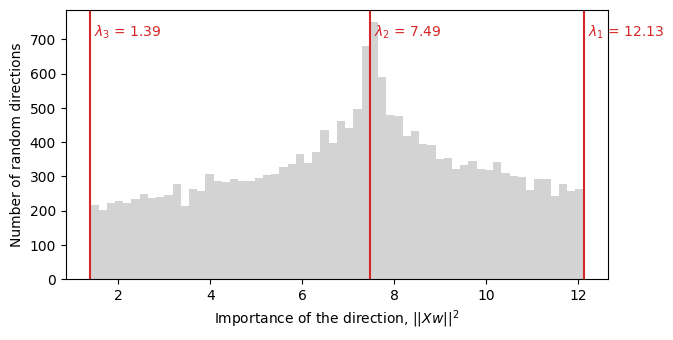

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(random_importance, bins=60, color="lightgray")
for j, eigenvalue in enumerate(eigenvalues, start=1):
    ax.axvline(eigenvalue, color="tab:red")
    ax.text(eigenvalue, ax.get_ylim()[1] * 0.95, f" $\\lambda_{j}$ = {eigenvalue:.2f}", color="tab:red", va="top")
ax.set_xlabel("Importance of the direction, $||Xw||^2$")
ax.set_ylabel("Number of random directions")
plt.show()

**Claim.** Over all unit vectors, $\lVert Xw \rVert^2$ is largest for $w = v_1$ (the value is $\lambda_1$) and smallest for $w = v_m$ (the value is $\lambda_m$).

*Reason.* Write $w = \sum_j c_j v_j$ with $\sum_j c_j^2 = 1$ (the $v_j$ form an orthonormal basis). Then

$$
w^\top X^\top X \, w = \sum_j \lambda_j c_j^2 ,
$$

a weighted average of the eigenvalues with weights $c_j^2$ that sum to 1. A weighted average cannot exceed the largest value, and it reaches $\lambda_1$ only if all the weight is on $v_1$.

In [11]:
# Check the weighted-average formula on a random direction
w_example = random_directions[0]
coefficients = V.T @ w_example   # c_j = v_j' w

print("Coefficients c_j:", coefficients)
print("Sum of c_j^2:", np.sum(coefficients ** 2).round(3))
print("Weighted average of the eigenvalues:", np.sum(eigenvalues * coefficients ** 2).round(3))
print("Importance of w:", importance(w_example).round(3))

Coefficients c_j: [ 0.224  0.79  -0.571]
Sum of c_j^2: 1.0
Weighted average of the eigenvalues: 5.734
Importance of w: 5.734


## The second direction

The best direction orthogonal to $v_1$ is $v_2$. Among all unit vectors with $w^\top v_1 = 0$, the coefficient $c_1$ is zero, so the average is over $\lambda_2$ and $\lambda_3$ only.

In [12]:
# Keep only the random directions that are (almost) orthogonal to v1
orthogonal_to_v1 = random_directions[np.abs(random_directions @ V[:, 0]) < 0.02]
orthogonal_importance = np.einsum("ij,jk,ik->i", orthogonal_to_v1, XtX, orthogonal_to_v1)

print("Number of directions:", len(orthogonal_to_v1))
print("Largest importance among them:", orthogonal_importance.max().round(3))
print("lambda_2:", eigenvalues[1].round(3))

Number of directions: 415
Largest importance among them: 7.487
lambda_2: 7.487


## The scores in the eigenvector directions

Scoring the documents with $v_j$ gives the vector $X v_j = \sigma_j u_j$, with $\sigma_j = \sqrt{\lambda_j}$. Its squared length is $\lambda_j$. These are the document coordinates of the SVD.

In [13]:
scores = X.to_numpy() @ V

score_table = pd.DataFrame(scores, index=documents, columns=["score v1", "score v2", "score v3"])
score_table.loc["sum of squares"] = (scores ** 2).sum(axis=0)
score_table.loc["lambda"] = eigenvalues
score_table

,score v1,score v2,score v3
doc1,1.712700,-1.316110,-0.578369
doc2,1.419413,-1.538056,0.787179
doc3,0.668663,-0.364722,-0.647973
doc4,2.594242,1.804425,0.118153
sum of squares,12.125275,7.486735,1.387991
lambda,12.125275,7.486735,1.387991


## The importance of the directions as shares

The eigenvalues add up to the total squared size of $X$:

$$
\sum_j \lambda_j = \operatorname{trace}(X^\top X) = \sum_{d, j} X_{dj}^2 = \lVert X \rVert_F^2 .
$$

So $\lambda_j / \sum_k \lambda_k$ is the share of the data explained by direction $j$.

In [14]:
print("Sum of eigenvalues:", eigenvalues.sum().round(3))
print("Trace of X'X:", np.trace(XtX))
print("Sum of squared entries of X:", np.sum(counts ** 2))

pd.DataFrame({
    "lambda": eigenvalues,
    "sigma": np.sqrt(eigenvalues),
    "share": eigenvalues / eigenvalues.sum(),
    "cumulative share": np.cumsum(eigenvalues) / eigenvalues.sum(),
}, index=["direction 1", "direction 2", "direction 3"]).round(3)

Sum of eigenvalues: 21.0
Trace of X'X: 21
Sum of squared entries of X: 21


,lambda,sigma,share,cumulative share
direction 1,12.125,3.482,0.577,0.577
direction 2,7.487,2.736,0.357,0.934
direction 3,1.388,1.178,0.066,1.000
